## Homework 9: Text Classification with Fine-Tuned BERT

### Due: Midnight on November 1st (with 2-hour grace period) — Worth 85 points

In this final homework, we’ll explore **fine-tuning pretrained Transformer models** for text classification using the **IMDB Movie Review** dataset. You’ll begin by training and evaluating a DistilBERT baseline, then conduct experiments to investigate how training configurations, dataset size, and model architecture affect predictive performance and computational cost.

You’ll complete three problems:

* **Problem 1:** Compare three context-length training configurations and their validation performance and training times. You’ll also compare your best configuration with the initial DistilBERT baseline.
* **Problem 2:** Measure how **training data size** affects both model performance and total training time.
* **Problem 3:** Compare **DistilBERT and BERT-base** to analyze the trade-offs between model size, accuracy, and training time.

In each problem, you’ll report experimental results, interpret the differences, and justify a choice based on validation performance and computational cost.

> **Note:** This homework was developed and tested on **Google Colab**, due to version conflicts when running locally. It is **strongly recommended** that you complete your work on Colab as well.

There are three problems with six graded questions in total. Each graded question is worth 14 points, with one additional point for completing the homework.


### Developing with Increasing Amounts of Data

Fine-tuning Transformer models can be computationally expensive. In this assignment, you will use a **progressive development workflow**: first verify that your code works with a small dataset, then increase the amount of training data as your experiments become more reliable.

The global `DATA_MODE` setting controls the training subset used for initial model development:

- `"smoke"` — 1% of training data, for checking that your code runs.
- `"dev"` — 10% of training data, for debugging and development.
- `"baseline"` — 25% of training data, for establishing a meaningful baseline.
- `"full"` — 100% of the training pool, when full-data training is needed.

The subsets are reproducible and nested: larger subsets contain the examples used in smaller subsets.

**Important:** The development setting affects only the training data. The validation and test sets remain fixed, so evaluation results are comparable. Do not use the test set to select models or tune hyperparameters.

The graded experiments in Problems 1–3 specify their own training-data fractions, independently of `DATA_MODE`. Changing this global setting does not change the datasets used in those experiments.

For the baseline, use `DATA_MODE = "baseline"`. For the graded experiments, follow the settings specified in each problem.


In [1]:
# Install once per new Colab runtime
%pip -q install -U keras keras-hub tensorflow tensorflow-text datasets evaluate

# ---- Backend BEFORE importing keras ----
import os
os.environ["KERAS_BACKEND"] = "tensorflow"

import time
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay
import keras
import keras_hub as kh
import evaluate
from datasets import load_dataset, Dataset, Features, Value, ClassLabel
from sklearn.model_selection import train_test_split

from keras import mixed_precision                    # generally faster
mixed_precision.set_global_policy("mixed_float16")

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
cudf-cu13 26.6.0 requires pyarrow<24,>=19.0.0, but you have pyarrow 26.0.0 which is incompatible.
keras-nlp 0.26.0 requires keras-hub==0.26.0, but you have keras-hub 0.32.0 which is incompatible.


### Here is where you can set global hyperparameters for this homework

In [2]:

# ------------ Global Configuration ------------

SEED = 42

# Model and training settings
MAX_LEN = 128
EPOCHS = 2
BATCH = 32
EVAL_BATCH = 64


# Development workflow
# Use "smoke" for debugging, "dev" for development,
# "baseline" for 25%, or "full" for 100%.

DATA_MODE = "baseline"

DATA_FRACTIONS = {
    "smoke":    0.01,   # 1% of training pool
    "dev":      0.10,   # 10% of training pool
    "baseline": 0.25,   # 25% of training pool
    "full":     1.00    # Entire training pool
}

assert DATA_MODE in DATA_FRACTIONS
TRAIN_FRAC = DATA_FRACTIONS[DATA_MODE]


keras.utils.set_random_seed(SEED)

print(f"Data mode: {DATA_MODE}")
print(f"Training fraction: {TRAIN_FRAC:.0%}")


Data mode: baseline
Training fraction: 25%


### Load and Preprocess the IMDB Movie Review Dataset

In [3]:

# ------------ Load and Partition IMDB ------------

imdb = load_dataset("stanfordnlp/imdb")

# Preserve the original held-out test set
test_ds = imdb["test"]

# Create a fixed, stratified validation set
indices = np.arange(len(imdb["train"]))

train_idx, val_idx = train_test_split(
    indices,
    test_size=0.10,
    random_state=SEED,
    stratify=np.array(imdb["train"]["label"])
)

train_pool = imdb["train"].select(train_idx.tolist())
val_ds = imdb["train"].select(val_idx.tolist())

# ------------ Reproducible Nested Training Subsets ------------

# Shuffle each class independently, then interleave classes.
# This gives balanced, nested training subsets.
rng = np.random.default_rng(SEED)

labels = np.array(train_pool["label"])
neg_idx = np.flatnonzero(labels == 0)
pos_idx = np.flatnonzero(labels == 1)

rng.shuffle(neg_idx)
rng.shuffle(pos_idx)

train_order = np.column_stack((neg_idx, pos_idx)).ravel()

def get_training_subset(frac):
    """Return a balanced, nested fraction of the training pool."""
    if not 0 < frac <= 1:
        raise ValueError("frac must be in (0, 1].")

    n_pairs = max(1, round(len(train_order) * frac / 2))
    selected = train_order[:2 * n_pairs]

    return train_pool.select(selected.tolist())

# Apply the development throttle
train_ds = get_training_subset(TRAIN_FRAC)

# ------------ NumPy Arrays for Keras ------------

X_tr = np.array(train_ds["text"], dtype=object)
y_tr = np.array(train_ds["label"], dtype="int32")

X_va = np.array(val_ds["text"], dtype=object)
y_va = np.array(val_ds["label"], dtype="int32")

X_te = np.array(test_ds["text"], dtype=object)
y_te = np.array(test_ds["label"], dtype="int32")

# ------------ Summary ------------

def _counts(ds):
    values = np.array(ds["label"], dtype=int)
    return len(values), np.bincount(values, minlength=2).tolist()

print(f"Data mode: {DATA_MODE} ({TRAIN_FRAC:.0%})")
print("Training pool:", _counts(train_pool))
print("Training subset:", _counts(train_ds))
print("Validation:", _counts(val_ds))
print("Test:", _counts(test_ds))


README.md:   0%|          | 0.00/7.81k [00:00<?, ?B/s]

plain_text/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 21.0MB            

plain_text/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

plain_text/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 20.5MB            

plain_text/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

plain_text/unsupervised-00000-of-00001.p(…): reconstructing file:   0%|          |  0.00B / 42.0MB            

plain_text/unsupervised-00000-of-00001.p(…): downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/25000 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/25000 [00:00<?, ? examples/s]

Generating unsupervised split:   0%|          | 0/50000 [00:00<?, ? examples/s]

Data mode: baseline (25%)
Training pool: (22500, [11250, 11250])
Training subset: (5624, [2812, 2812])
Validation: (2500, [1250, 1250])
Test: (25000, [12500, 12500])


### Build and train a baseline Distil-Bert Text Classifier

In [4]:

# ---- DistilBERT baseline: develop using the selected data throttle ----

print(f"Data mode: {DATA_MODE}")
print(f"Training examples: {len(X_tr):,}")
print(f"Validation examples: {len(X_va):,}")
print(f"Maximum sequence length: {MAX_LEN}")
print(f"Batch size: {BATCH}")

# Build preprocessor and classifier
keras.utils.set_random_seed(SEED)

preproc = kh.models.DistilBertTextClassifierPreprocessor.from_preset(
    "distil_bert_base_en_uncased",
    sequence_length=MAX_LEN
)

model = kh.models.DistilBertTextClassifier.from_preset(
    "distil_bert_base_en_uncased",
    num_classes=2,
    preprocessor=preproc
)

model.compile(
    optimizer=keras.optimizers.Adam(1e-5),
    loss=keras.losses.SparseCategoricalCrossentropy(from_logits=True),
    metrics=[keras.metrics.SparseCategoricalAccuracy(name="acc")]
)

# ---- Train with early stopping ----

cb = [
    keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=2,
        restore_best_weights=True
    )
]

start = time.perf_counter()

history = model.fit(
    X_tr, y_tr,
    validation_data=(X_va, y_va),
    epochs=EPOCHS,
    batch_size=BATCH,
    callbacks=cb,
    verbose=1
)

elapsed = time.perf_counter() - start

# ---- Evaluate the restored model on validation data ----

val_loss, val_acc = model.evaluate(
    X_va, y_va,
    batch_size=EVAL_BATCH,
    verbose=0
)

logits = model.predict(
    X_va,
    batch_size=EVAL_BATCH,
    verbose=0
)

y_pred = np.argmax(logits, axis=-1)

acc_metric = evaluate.load("accuracy")
f1_metric = evaluate.load("f1")

acc = acc_metric.compute(
    predictions=y_pred,
    references=y_va
)["accuracy"]

f1 = f1_metric.compute(
    predictions=y_pred,
    references=y_va
)["f1"]

# ---- Confusion matrix ----

def confusion_matrix_np(y_true, y_pred, num_classes=2):
    cm = np.zeros((num_classes, num_classes), dtype=int)
    for t, p in zip(y_true, y_pred):
        cm[t, p] += 1
    return cm

# ---- Summary ----

best_epoch = np.argmin(history.history["val_loss"]) + 1

print(f"\nBest epoch: {best_epoch}")
print(f"Validation loss (restored model): {val_loss:.4f}")
print(f"Validation accuracy: {acc:.4f}")
print(f"Validation F1: {f1:.4f}")

print("\nValidation confusion matrix:")
print(confusion_matrix_np(y_va, y_pred))

print("\nTraining time:",
      time.strftime("%H:%M:%S", time.gmtime(elapsed)))


Data mode: baseline
Training examples: 5,624
Validation examples: 2,500
Maximum sequence length: 128
Batch size: 32


/usr/local/lib/python3.13/dist-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a grain dataset. The grain dataset is expected to already be shuffled.
  self.data_adapter = data_adapters.get_data_adapter(


Epoch 1/2
176/176 ━━━━━━━━━━━━━━━━━━━━ 488s 2s/step - acc: 0.7637 - loss: 0.4947 - val_acc: 0.8452 - val_loss: 0.3564
Epoch 2/2
176/176 ━━━━━━━━━━━━━━━━━━━━ 332s 2s/step - acc: 0.8604 - loss: 0.3283 - val_acc: 0.8460 - val_loss: 0.3630



Best epoch: 1
Validation loss (restored model): 0.3564
Validation accuracy: 0.8452
Validation F1: 0.8451

Validation confusion matrix:
[[1057  193]
 [ 194 1056]]

Training time: 00:13:53



# Problem 1 — Mini Sweep: Context Length and Training Cost (3 Runs)

In this problem, we'll investigate how **context length** (`MAX_LEN`) affects the performance and computational cost of fine-tuning DistilBERT.

A longer context allows the model to use more of each text, potentially improving its predictions. However, longer sequences require more computation and memory, particularly because of the attention mechanism.

We'll compare three configurations, using different batch sizes and learning rates appropriate for each context length.

## Setup (keep these fixed)

* `SUBSET_FRAC = 0.25` — use 25% of the training dataset.
* `EPOCHS = 2` — maximum number of training epochs.
* **EarlyStopping** with `restore_best_weights=True`.
* Same random seed for all runs.
* Same training and validation examples for all runs (don't reshuffle or resplit between runs).

## Run these 3 configurations

| MAX_LEN | Learning rate | Batch size |
|---|---|---|
| 128 | `2e-5` | 32 |
| 256 | `1e-5` | 16 |
| 512 | `7.5e-6` | 8 |

These configurations represent progressively longer contexts, with smaller batch sizes to accommodate the increased memory requirements.

**Important:** Because learning rate and batch size also change, this experiment compares three practical training configurations. It does not isolate the effect of context length alone.

For each run, record:

* Best validation loss and the epoch at which it occurred.
* Validation accuracy at that epoch.
* Total training time.

Identify the configuration with the **lowest validation loss**. Problems 2 and 3 use their own fixed configurations to isolate the effects being studied.

## If you encounter an Out of Memory error

* At `MAX_LEN = 256`, reduce `BATCH` from 16 to 8.
* At `MAX_LEN = 512`, reduce `BATCH` from 8 to 4.

If you make such a change, record it when discussing your results.

Then answer the graded questions.


In [5]:
from IPython.display import display, Markdown, HTML
from sklearn.metrics import ConfusionMatrixDisplay

/usr/local/lib/python3.13/dist-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a grain dataset. The grain dataset is expected to already be shuffled.
  self.data_adapter = data_adapters.get_data_adapter(


Epoch 1/2
176/176 ━━━━━━━━━━━━━━━━━━━━ 495s 2s/step - acc: 0.7889 - loss: 0.4531 - val_acc: 0.8484 - val_loss: 0.3480
Epoch 2/2
176/176 ━━━━━━━━━━━━━━━━━━━━ 337s 2s/step - acc: 0.8846 - loss: 0.2897 - val_acc: 0.8384 - val_loss: 0.4024


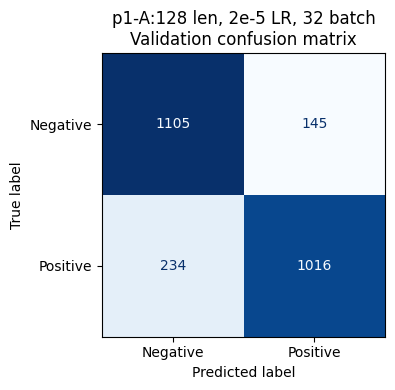

/usr/local/lib/python3.13/dist-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a grain dataset. The grain dataset is expected to already be shuffled.
  self.data_adapter = data_adapters.get_data_adapter(


Epoch 1/2
352/352 ━━━━━━━━━━━━━━━━━━━━ 520s 1s/step - acc: 0.8293 - loss: 0.3887 - val_acc: 0.8812 - val_loss: 0.2961
Epoch 2/2
352/352 ━━━━━━━━━━━━━━━━━━━━ 372s 1s/step - acc: 0.9132 - loss: 0.2264 - val_acc: 0.8820 - val_loss: 0.3112


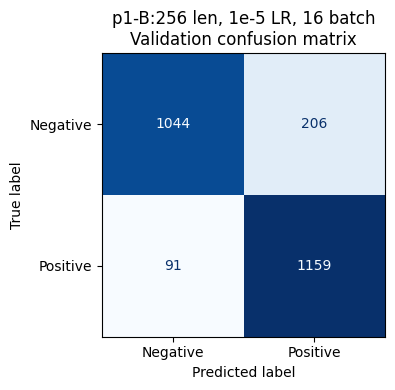

100%|██████████| 462/462 [00:00<00:00, 801kB/s]


100%|██████████| 794/794 [00:00<00:00, 1.43MB/s]


100%|██████████| 226k/226k [00:00<00:00, 286kB/s]


100%|██████████| 253M/253M [00:18<00:00, 14.6MB/s]
/usr/local/lib/python3.13/dist-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a grain dataset. The grain dataset is expected to already be shuffled.
  self.data_adapter = data_adapters.get_data_adapter(


Epoch 1/2
703/703 ━━━━━━━━━━━━━━━━━━━━ 542s 679ms/step - acc: 0.8485 - loss: 0.3552 - val_acc: 0.9048 - val_loss: 0.2528
Epoch 2/2
703/703 ━━━━━━━━━━━━━━━━━━━━ 435s 620ms/step - acc: 0.9214 - loss: 0.2130 - val_acc: 0.8904 - val_loss: 0.3000


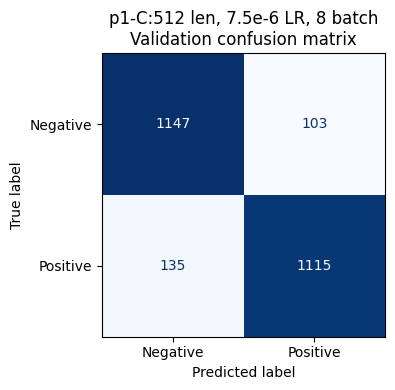

In [6]:
# Your code here; add as many cells as you need
def format_hms(seconds):
    """Format elapsed seconds as H:MM:SS."""
    return time.strftime("%H:%M:%S", time.gmtime(seconds))


Results = {}

best_idx = int(np.argmin(history.history["val_loss"]))

Results["baseline_distilBert"] = {
    "min_val_loss": float(history.history["val_loss"][best_idx]),
    "val_accuracy": float(history.history["val_acc"][best_idx]),
    "best_epoch": best_idx + 1,
    "max_len": MAX_LEN,
    "learning_rate": 1e-5,
    "batch_size": BATCH,
    "n_train": len(X_tr),
    "training_seconds": float(elapsed),
    "processing_time": format_hms(elapsed),
}

def p1_model(
    MAX_LEN, LR, BATCH,
    EPOCHS=2, EVAL_BATCH=64,
    SEED=42,
):
    ## __ Reset model-building state and seed for each experiment
    keras.backend.clear_session()
    keras.utils.set_random_seed(SEED)

    ## __ Preprocess
    preprocessor = (
        kh.models.DistilBertTextClassifierPreprocessor
        .from_preset(
            "distil_bert_base_en_uncased",
            sequence_length=MAX_LEN,
        )
    )

    model = (
        kh.models.DistilBertTextClassifier
        .from_preset(
            "distil_bert_base_en_uncased",
            num_classes=2,
            preprocessor=preprocessor,
        )
    )

    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=LR),
        loss=keras.losses.SparseCategoricalCrossentropy(
            from_logits=True,
        ),
        metrics=[keras.metrics.SparseCategoricalAccuracy(name="acc")],
    )

    early_stopping_cb = keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=2,
        restore_best_weights=True,
    )

    ## __ Train model
    start = time.perf_counter()

    history = model.fit(
        X_tr,
        y_tr,
        validation_data=(X_va, y_va),
        epochs=EPOCHS,
        batch_size=BATCH,
        callbacks=[early_stopping_cb],
    )

    elapsed = time.perf_counter() - start

    ## __ Predict using the restored best weights
    logits = model.predict(
        X_va,
        batch_size=EVAL_BATCH,
        verbose=0,
    )
    y_pred = np.argmax(logits, axis=-1)

    return history, elapsed, y_pred

## __ Experiment settings
p1_experiment_config = {
    "p1-A:128 len, 2e-5 LR, 32 batch": dict(
        MAX_LEN=128, LR=2e-5, BATCH=32,
    ),
    "p1-B:256 len, 1e-5 LR, 16 batch": dict(
        MAX_LEN=256, LR=1e-5, BATCH=16,
    ),

    "p1-C:512 len, 7.5e-6 LR, 8 batch": dict(
        MAX_LEN=512, LR=7.5e-6, BATCH=8,
    ),
    # "p1-C:512 len, 7.5e-6 LR, 4 batch": dict(
    #     MAX_LEN=512, LR=7.5e-6, BATCH=4,
    # ),
}

## __ Preserve existing baseline results, if any
if "Results" not in globals():
    Results = {}

SHOW_MATRIX = True


## __ Run experiments
for title, config in p1_experiment_config.items():
    display(HTML(f"<h2>{title}</h2>"))

    history, elapsed, y_pred = p1_model(**config)

    ## __ Select metrics from the same best epoch
    best_idx = int(np.argmin(history.history["val_loss"]))

    Results[title] = {
        "min_val_loss": float(history.history["val_loss"][best_idx]),
        "val_accuracy": float(history.history["val_acc"][best_idx]),
        "best_epoch": best_idx + 1,
        "max_len": config["MAX_LEN"],
        "learning_rate": config["LR"],
        "batch_size": config["BATCH"],
        "n_train": len(X_tr),
        "training_seconds": float(elapsed),
        "processing_time": format_hms(elapsed),
    }

    ## __ Optional labeled confusion matrix
    if SHOW_MATRIX:
        fig, ax = plt.subplots(figsize=(5, 4))

        ConfusionMatrixDisplay.from_predictions(
            y_va,
            y_pred,
            labels=[0, 1],
            display_labels=["Negative", "Positive"],
            cmap="Blues",
            values_format="d",
            colorbar=False,
            ax=ax,
        )

        ax.set_title(f"{title}\nValidation confusion matrix")
        plt.tight_layout()
        plt.show()



### Graded Questions

In [7]:
# Set a1a to the validation accuracy at the epoch with minimum
# validation loss for the configuration with the lowest validation loss.
p1_result = (
        pd.DataFrame(Results)
        .T
        .reset_index()
        .rename(columns={"index": "model"})
        .query("model.str.startswith('p1')")
        .sort_values(by="min_val_loss", ascending=True)

    )

a1a = float(p1_result["val_accuracy"].iloc[0])                                       # Replace 0.0 with your answer

In [8]:
# Graded Answer
# DO NOT change this cell in any way

print(f'a1a = {a1a:.4f}')

a1a = 0.9048


### Question a1b:

* How did validation accuracy change across the three context lengths (128 → 256 → 512)? Were the improvements equally large?
* How did training time change as context length increased?
* Compare the best Problem 1 configuration with the initial DistilBERT baseline. How much did validation accuracy improve, and what additional training time was required?
* Which configuration would you choose, considering both validation performance and computational cost? Explain your reasoning.

**Note:** Because learning rate and batch size also changed, you cannot attribute the differences in performance solely to context length.


In [ ]:
a1b = """
When comparing the increase of context lenght, such as doubling and quadrupling the context length,
the validation loss does decrease by quite much (such as from 0.35 down to 0.30 and 0.25, which is about about 14% each).
However, the validation accuracy does not increase as much. 
As the training time only increases by 1-min per increase, the cost of processing time is not that high.

While the 128 lenght context is pretty similar to the baseline model metrics, the 512 lenght performs much better than the baseline.

The current setting for the 512 context length is unfortunately not exactly the same as the other models, 
so the comparison is not exactly on the same footing. 
However, the 512 context lenght model performs well and a good model to choose. 

"""



In [10]:
# Graded Answer
# DO NOT change this cell in any way

print(f'a1b = {a1b}')

a1b = 
Your answer here



# Problem 2 — How Much Data Is Enough? (3 Runs)

In this problem, you'll investigate how the amount of training data affects the performance and computational cost of fine-tuning DistilBERT.

More training data generally improves predictive performance, but also increases training time. We want to determine whether the additional improvement is worth the computational cost.

## Setup

* Use a fixed DistilBERT configuration: `MAX_LEN = 256`, `LR = 1e-5`, and `BATCH = 16`, independently of the selected configuration in Problem 1.
* Keep the validation dataset fixed across all runs.
* Use `EPOCHS = 2` and EarlyStopping with `restore_best_weights=True`.
* Use the same random seed for all runs.

## Run these 3 configurations

| SUBSET_FRAC | Training data |
|---|---|
| 0.25 | 25% of the training set |
| 0.50 | 50% of the training set |
| 1.00 | 100% of the training set |

For each run, record:

* Best validation loss and the epoch at which it occurred.
* Validation accuracy at that epoch.
* Total training time.

Select the configuration with the lowest validation loss.

Then answer the graded questions.



In [11]:
# Your code here; add as many cells as you need
p2_experiment_config = {
    "p2-A:25% data":        dict(SUBSET_FRAC=0.25),
    "p2-B:50% data":        dict(SUBSET_FRAC=0.50),
    "p2-C:100% data":       dict(SUBSET_FRAC=1.00),
}

#--default
p2_model_config = dict(
    MAX_LEN=256,
    LR=1e-5,
    BATCH=16,
    # EPOCHS=2,
)


#---experiment
for p2_title, p2_config in p2_experiment_config.items():
    display(HTML(f"<h2>{p2_title}</h2>"))

    ##---rebuild training data
    train_ds = get_training_subset(p2_config["SUBSET_FRAC"])
    X_tr = np.array(train_ds["text"], dtype= object)
    y_tr = np.array(train_ds["label"], dtype= "int32")

    ##-- reusing the p1 model
    history, elapsed, y_pred = p1_model(**p2_model_config)

    best_idx = int(np.argmin(history.history["val_loss"]))

    Results[p2_title] = {
        "min_val_loss": float(history.history["val_loss"][best_idx]),
        "val_accuracy": float(history.history["val_acc"][best_idx]),
        "best_epoch": best_idx + 1,
        "max_len": p2_model_config["MAX_LEN"],
        "learning_rate": p2_model_config["LR"],
        "batch_size": p2_model_config["BATCH"],
        "n_train": len(X_tr),
        "training_seconds": float(elapsed),
        "processing_time": format_hms(elapsed),
    }

/usr/local/lib/python3.13/dist-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a grain dataset. The grain dataset is expected to already be shuffled.
  self.data_adapter = data_adapters.get_data_adapter(


Epoch 1/2
352/352 ━━━━━━━━━━━━━━━━━━━━ 469s 1s/step - acc: 0.8297 - loss: 0.3886 - val_acc: 0.8816 - val_loss: 0.2964
Epoch 2/2
352/352 ━━━━━━━━━━━━━━━━━━━━ 378s 1s/step - acc: 0.9138 - loss: 0.2262 - val_acc: 0.8816 - val_loss: 0.3125


Epoch 1/2
704/704 ━━━━━━━━━━━━━━━━━━━━ 755s 1s/step - acc: 0.8542 - loss: 0.3408 - val_acc: 0.8932 - val_loss: 0.2653
Epoch 2/2
704/704 ━━━━━━━━━━━━━━━━━━━━ 652s 927ms/step - acc: 0.9179 - loss: 0.2146 - val_acc: 0.8964 - val_loss: 0.2778


Epoch 1/2
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 1280s 879ms/step - acc: 0.8736 - loss: 0.3022 - val_acc: 0.9036 - val_loss: 0.2354
Epoch 2/2
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 1175s 836ms/step - acc: 0.9235 - loss: 0.1989 - val_acc: 0.9012 - val_loss: 0.2361


### Graded Questions

In [12]:
# Set a2a to the validation accuracy at the epoch with minimum
# validation loss for the configuration with the lowest validation loss.
p2_result = (
        pd.DataFrame(Results)
        .T
        .reset_index()
        .rename(columns={"index": "model"})
        .query("model.str.startswith('p2')")
        .sort_values(by="min_val_loss", ascending=True)

    )

a2a = float(p2_result["val_accuracy"].iloc[0])

In [13]:
# Graded Answer
# DO NOT change this cell in any way

print(f'a2a = {a2a:.4f}')

a2a = 0.9036


### Question a2b:

* How did validation accuracy change as the training dataset increased from 25% to 50% to 100%? Were the improvements equally large?
* How did training time change as the dataset increased?
* Which dataset size would you choose, considering both predictive performance and computational cost? Explain your reasoning using your results.


In [14]:
a2b = """
Your answer here
"""



In [15]:
## Graded Answer
# DO NOT change this cell in any way

print(f'a2b = {a2b}')

a2b = 
Your answer here



# Problem 3 — Model Swap: Speed vs. Accuracy (2 Runs)

In this problem, we'll compare two pretrained Transformer models with different capacities:

* **DistilBERT** — a smaller, computationally efficient model.
* **BERT-base** — a larger model with greater capacity, but higher computational cost.

Both models can be fine-tuned for the same text classification task. Our goal is to determine whether the larger model's improvement in predictive performance justifies its additional training time.

## Setup

Use the following settings for both models:

* `MAX_LEN = 256`
* `LR = 1e-5`
* `BATCH = 16`
* `SUBSET_FRAC = 0.50`
* `EPOCHS = 2`
* EarlyStopping with `restore_best_weights=True`
* Same random seed
* Same training and validation examples

Only the model architecture changes.

## Run these 2 configurations

| Model | Pretrained preset |
|---|---|
| DistilBERT | `distil_bert_base_en_uncased` |
| BERT-base | `bert_base_en_uncased` |

## How to switch models

**DistilBERT:**

```python
preproc = kh.models.DistilBertTextClassifierPreprocessor.from_preset(
    "distil_bert_base_en_uncased", sequence_length=MAX_LEN
)
model = kh.models.DistilBertTextClassifier.from_preset(
    "distil_bert_base_en_uncased", num_classes=2, preprocessor=preproc
)
```

**BERT-base:**

```python
preproc = kh.models.BertTextClassifierPreprocessor.from_preset(
    "bert_base_en_uncased", sequence_length=MAX_LEN
)
model = kh.models.BertTextClassifier.from_preset(
    "bert_base_en_uncased", num_classes=2, preprocessor=preproc
)
```

## What to do

Train and evaluate both models using the same experimental settings.

For each model, record:

* Best validation loss and the epoch at which it occurred.
* Validation accuracy at that epoch.
* Total training time.

Compare the results, then answer the graded questions.

**Note:** This experiment compares models under the same training budget, not necessarily at their individually optimal hyperparameters.


In [16]:
# Your code here; add as many cells as you wish

## not doing the p3a since its the same....
Results["p3-A:DistilBERT"] = Results["p2-B:50% data"].copy()

#----- set different thng
p3_train_ds = get_training_subset(0.50)
p3_X_tr = np.array(p3_train_ds["text"], dtype= object)
p3_y_tr = np.array(p3_train_ds["label"], dtype= "int32")


def p3_model(
    model_type,
    MAX_LEN, LR, BATCH,
    EPOCHS=2, EVAL_BATCH=64,
    SEED=42,
):
    ## __ Reset model-building state and seed for each experiment
    keras.backend.clear_session()
    keras.utils.set_random_seed(SEED)

    ##_____ make the option for models _____ ##:
    if model_type == 'BERT-base':
        preprocessor = (
            kh.models.BertTextClassifierPreprocessor
            .from_preset(
                "bert_base_en_uncased",
                sequence_length=MAX_LEN,
            )
        )

        model = (
            kh.models.BertTextClassifier
            .from_preset(
                "bert_base_en_uncased",
                num_classes=2,
                preprocessor=preprocessor,
            )
        )

    elif model_type == 'DistilBERT':
        preprocessor = (
            kh.models.DistilBertTextClassifierPreprocessor
            .from_preset(
                "distil_bert_base_en_uncased",
                sequence_length=MAX_LEN,
            )
        )

        model = (
            kh.models.DistilBertTextClassifier
            .from_preset(
                "distil_bert_base_en_uncased",
                num_classes=2,
                preprocessor=preprocessor,
            )
        )

    else:
        raise ValueError(f"Unsupported model_type: {model_type}")

    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=LR),
        loss=keras.losses.SparseCategoricalCrossentropy(
            from_logits=True,
        ),
        metrics=[keras.metrics.SparseCategoricalAccuracy(name="acc")],
    )

    early_stopping_cb = keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=2,
        restore_best_weights=True,
    )

    ## __ Train model
    start = time.perf_counter()

    history = model.fit(
        p3_X_tr,
        p3_y_tr,
        validation_data=(X_va, y_va),
        epochs=EPOCHS,
        batch_size=BATCH,
        callbacks=[early_stopping_cb],
    )

    elapsed = time.perf_counter() - start

    ## __ Predict using the restored best weights
    logits = model.predict(
        X_va,
        batch_size=EVAL_BATCH,
        verbose=0,
    )
    y_pred = np.argmax(logits, axis=-1)

    return history, elapsed, y_pred

/usr/local/lib/python3.13/dist-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a grain dataset. The grain dataset is expected to already be shuffled.
  self.data_adapter = data_adapters.get_data_adapter(


Epoch 1/2
704/704 ━━━━━━━━━━━━━━━━━━━━ 780s 1s/step - acc: 0.8636 - loss: 0.3180 - val_acc: 0.9056 - val_loss: 0.2413
Epoch 2/2
704/704 ━━━━━━━━━━━━━━━━━━━━ 640s 911ms/step - acc: 0.9340 - loss: 0.1825 - val_acc: 0.9076 - val_loss: 0.2566


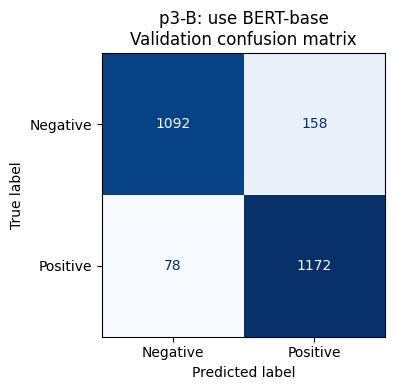

In [17]:
p3_experiment_config = {
    "p3-B: use BERT-base": dict(
        model_type='BERT-base',
        MAX_LEN=256, LR=1e-5, BATCH=16,
    ),
}

SHOW_MATRIX = True

## __ Run experiments
for title, config in p3_experiment_config.items():
    display(HTML(f"<h2>{title}</h2>"))

    history, elapsed, y_pred = p3_model(**config)

    ## __ Select metrics from the same best epoch
    best_idx = int(np.argmin(history.history["val_loss"]))

    Results[title] = {
        "min_val_loss": float(history.history["val_loss"][best_idx]),
        "val_accuracy": float(history.history["val_acc"][best_idx]),
        "best_epoch": best_idx + 1,
        "max_len": config["MAX_LEN"],
        "learning_rate": config["LR"],
        "batch_size": config["BATCH"],
        "n_train": len(p3_X_tr),
        "training_seconds": float(elapsed),
        "processing_time": format_hms(elapsed),
    }

    ## __ Optional labeled confusion matrix
    if SHOW_MATRIX:
        fig, ax = plt.subplots(figsize=(5, 4))

        ConfusionMatrixDisplay.from_predictions(
            y_va,
            y_pred,
            labels=[0, 1],
            display_labels=["Negative", "Positive"],
            cmap="Blues",
            values_format="d",
            colorbar=False,
            ax=ax,
        )

        ax.set_title(f"{title}\nValidation confusion matrix")
        plt.tight_layout()
        plt.show()



### Graded Questions

In [18]:
# Set a3a to the validation accuracy at the epoch with minimum
# validation loss for the model with the lowest validation loss.
p3_result = (
        pd.DataFrame(Results)
        .T
        .reset_index()
        .rename(columns={"index": "model"})
        .query("model.str.startswith('p3')")
        .sort_values(by="min_val_loss", ascending=True)

    )

a3a = p3_result.iloc[0]["val_accuracy"]  # Replace 0.0 with your answer

In [19]:
# Graded Answer
# DO NOT change this cell in any way

print(f'a3a = {a3a:.4f}')

a3a = 0.9056


### Question a3b:

* Which model achieved the higher validation accuracy? How large was the difference?
* How did their total training times compare?
* Given limited computational resources, which model would you choose? Explain whether the improvement in predictive performance justifies the additional computational cost.


In [20]:
a3b = """
Your answer here
"""



In [21]:
## Graded Answer
# DO NOT change this cell in any way

print(f'a3b = {a3b}')

a3b = 
Your answer here



----

# result

In [22]:
(pd.DataFrame(Results)
        .T
        .reset_index()
        .rename(columns={"index": "model"})
        .sort_values(by="min_val_loss", ascending=True)
)


,model,min_val_loss,val_accuracy,best_epoch,max_len,learning_rate,batch_size,n_train,training_seconds,processing_time
6,p2-C:100% data,0.235368,0.9036,1,256,0.00001,16,22500,2463.632043,00:41:03
8,p3-B: use BERT-base,0.241299,0.9056,1,256,0.00001,16,11250,1429.886573,00:23:49
3,"p1-C:512 len, 7.5e-6 LR, 8 batch",0.252757,0.9048,1,512,0.000008,8,5624,981.909472,00:16:21
5,p2-B:50% data,0.265324,0.8932,1,256,0.00001,16,11250,1416.040141,00:23:36
7,p3-A:DistilBERT,0.265324,0.8932,1,256,0.00001,16,11250,1416.040141,00:23:36
2,"p1-B:256 len, 1e-5 LR, 16 batch",0.296075,0.8812,1,256,0.00001,16,5624,902.525071,00:15:02
4,p2-A:25% data,0.296396,0.8816,1,256,0.00001,16,5624,855.143905,00:14:15
1,"p1-A:128 len, 2e-5 LR, 32 batch",0.348023,0.8484,1,128,0.00002,32,5624,846.349647,00:14:06
0,baseline_distilBert,0.356438,0.8452,1,128,0.00001,32,5624,833.98632,00:13:53
